In [41]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
import pandas as pd

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

In [53]:
from plotting_ts_tools import (
    calculate_anomaly,
    line_plot,
    line_plot_min_max,
    cleanup,
    adjust_names,
    adjust_length,
    line_plot_anomaly,
    load_era5_csv,
    load_rcms_csv
)

In [112]:
# Define Variables
# 50 mm sind sehr wenige
# TR, Regcm hat zu viele sieht komisch aus
#index='R20mm' 
#index= 'DD'
#index= 'TG'
#index='SU40'
#index='TR26'
index='RRm'

country='Burkina Faso'
timestep='year'
longnameK='mean temperature [K]'

#longname='number of days with pr > 20 mm per day'  
#longname='number of dry days'  
#longname='mean temperature [°C]'
#longname='number of days with Tmax > 40°C'
#longname='number of days with Tmin > 26°C'
longname='mean daily precipitation amount [mm/day]'

In [113]:
# Load the CSV file
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_afr22/'+index
file_name='climdexCORDEX_AFR22_'+index+'_'+timestep+'_weighted_means.csv'
file_path = os.path.join(path,file_name)
data = pd.read_csv(file_path)

In [114]:
# Add ERA5
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_era5'
file_name='climdexERA5_'+index+'_'+timestep+'_weighted_means.csv'
era5_path = os.path.join(path,file_name)
era5data = pd.read_csv(era5_path)

In [115]:
# define output path and filename
outputpath='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries'
#outfile = os.path.join(outputpath,index+'_'+timestep+'_line_plot_sce_color_min_max.png')

if not os.path.exists(outputpath):
    os.makedirs(outputpath)

In [116]:
cut_data=load_rcms_csv(file_path, country, index, longname, start_date='1971-01-01', end_date='2098-12-31', longnameK=None)
#cut_data[:3] 

GCMcolor


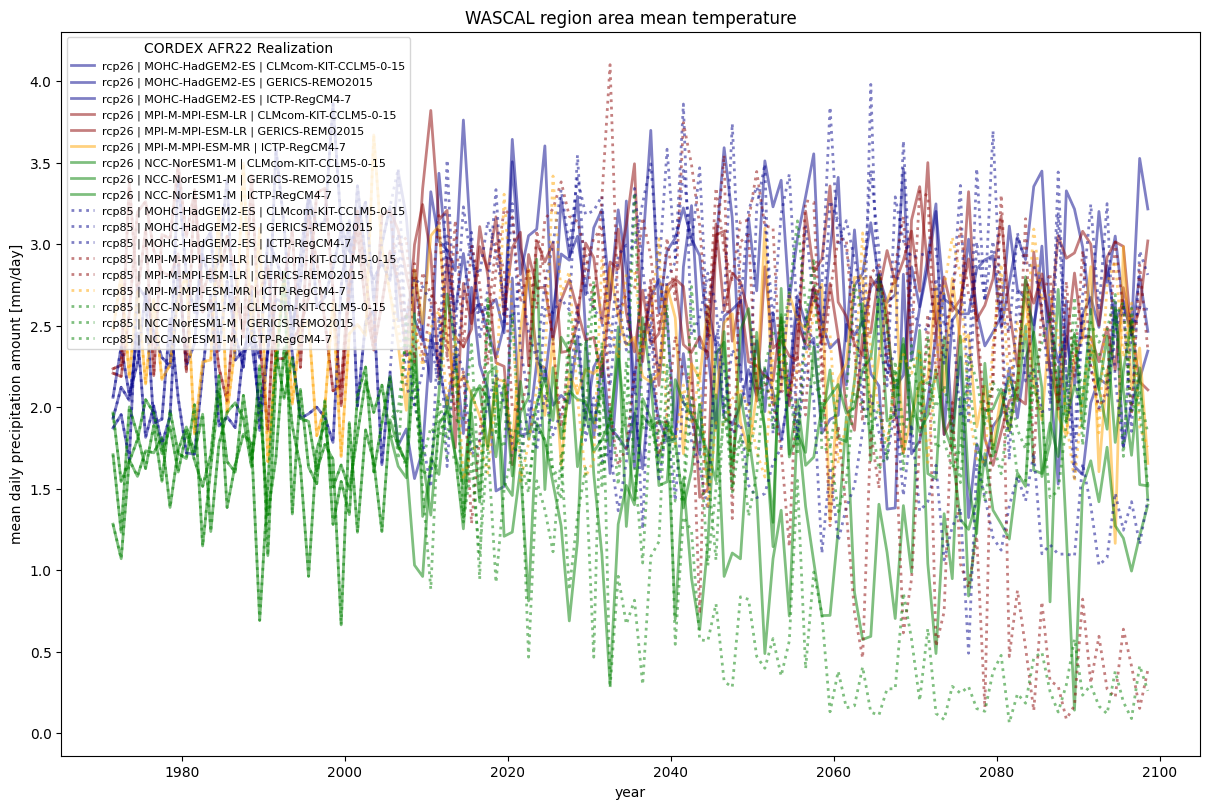

In [117]:
# make plot
# You can group by differet topic
# * GCMcolor
# * RCMcolor
# * Scenario
#line_plot(cut_data,'year', longname,'Scenario', index, outputpath)

#line_plot(cut_data,'year', longname,'RCMcolor', index, outputpath)
line_plot(cut_data,'year', longname,'GCMcolor', index, outputpath)



In [118]:
# prepare era5 data
era5_cut=load_era5_csv(era5_path, country, index, longname, start_date='1971-01-01', longnameK=longnameK)

Text(0, 0.5, 'mean daily precipitation amount [mm/day]')

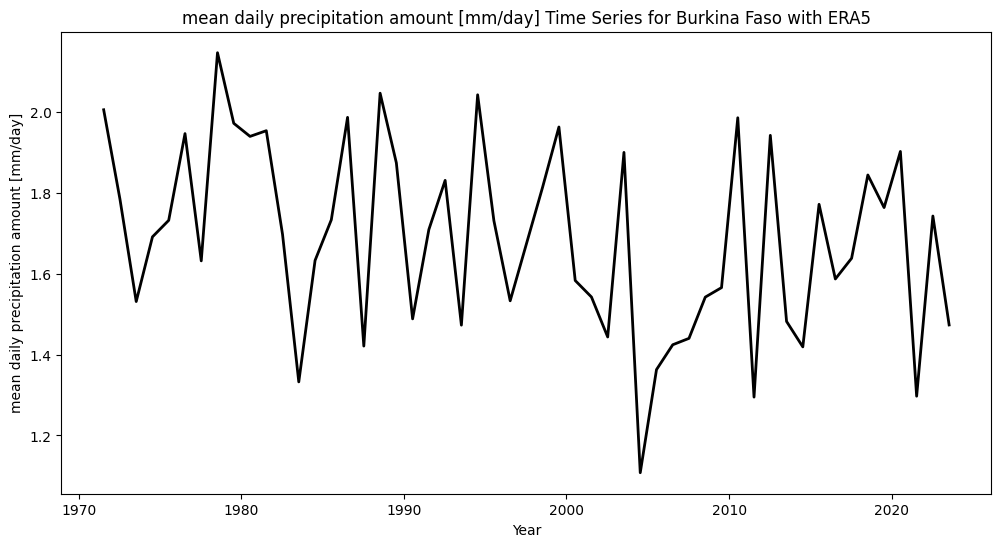

In [119]:
# just to look at era5
plt.figure(figsize=(12, 6))
plt.plot(era5_cut['year'], era5_cut[longname], label='ERA5', color='black', linewidth=2)
plt.title(f'{longname} Time Series for {country} with ERA5')
plt.xlabel('Year')
plt.ylabel(longname)

Plotting column:  mean daily precipitation amount [mm/day]
year mean daily precipitation amount [mm/day]
year mean daily precipitation amount [mm/day]
Saved plot to:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries/line_plot_min_max_RRm_year_Burkina_Faso.png


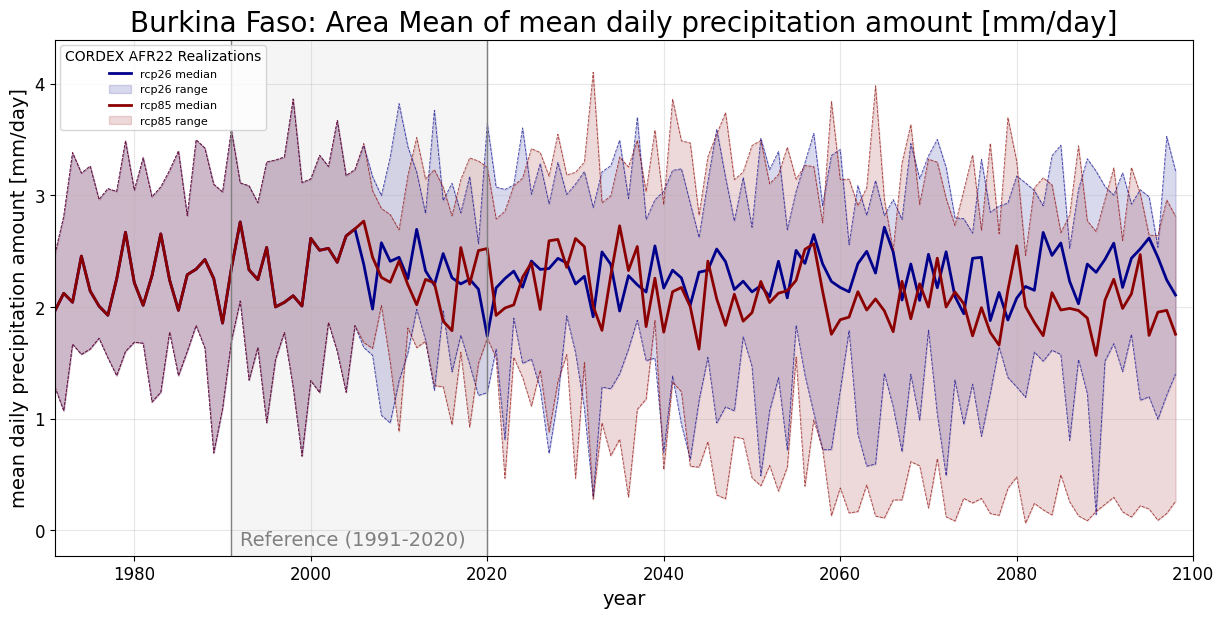

In [121]:
# You can chose if you like to add ERA5 or not
line_plot_min_max(cut_data,'year',longname,index,outputpath,country)#, ylim=(23,37))
#line_plot_min_max(cut_data,'year',longname,index,outputpath,country, dfera5=era5_cut)#, ylim=(23,37))


In [122]:
# calculate anomalies
# Returns dataframe with columns: anomaly, running_mean_10yr, running_mean_30yr
df = calculate_anomaly(cut_data, '1991-01-01', '2020-12-31', longname)
#df.head()

In [123]:
df_era5 = calculate_anomaly(era5_cut, '1991-01-01', '2020-12-31', longname)
#df_era5.head()

file liegt:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries/line_plot_scenario_min_max_year_RRm_anomaly.png


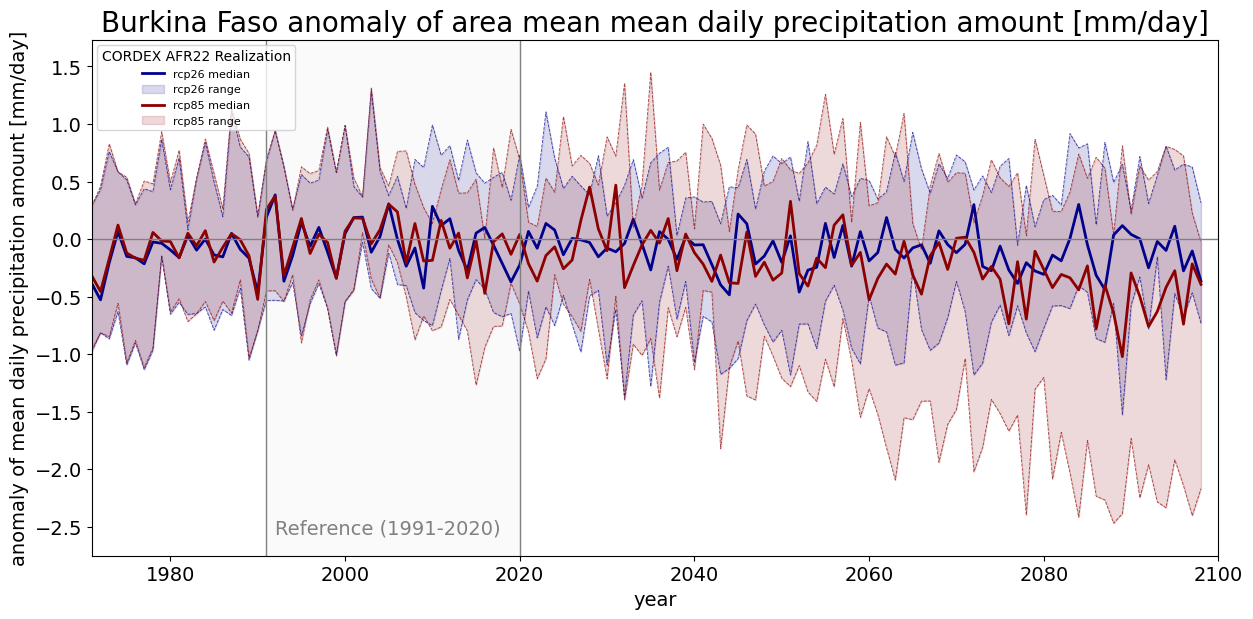

In [125]:
# make line plot with or without ERA5
#  make line plot of anomaly
# you can chose if you like to group by scenario or not
# you can chose if you like:
    # anomaly or running_mean_10yr or running_mean_30yr

#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario', country, index, longname)
#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario_min_max', country, index, longname) #,ylim=(-3,10))
#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'model', country, index, longname)
#line_plot_anomaly(df, 'year', 'running_mean_10yr', outputpath, 'model', country, index,longname)
#line_plot_anomaly(df, 'year', 'running_mean_30yr', outputpath, 'model', country, index,longname)
line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario_min_max', country, index, longname)
#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario_min_max', country, index, longname, era5=df_era5)